In [1]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Initialize simulator and shot count
simulator = AerSimulator()
SHOTS = 100

print("Libraries imported successfully!")

Libraries imported successfully!


# Challenge 2: Make the Quantum Coin Biased
**Name:** POLAMARASETTY JAGADEESH 
**Event:** Qiskit Fall Fest 2026 - Vishnu Institute of Technology  

## Theoretical Predictions ("Think Before You Run")

A fair quantum coin uses a Hadamard gate to create equal probabilities:
$$\vert{}\psi\rangle = \frac{1}{\sqrt{2}}\vert{}0\rangle + \frac{1}{\sqrt{2}}\vert{}1\rangle \implies P(0) = 50\%, \; P(1) = 50\%$$

To bias the quantum coin, we use the single-qubit rotation gate $R_y(\theta)$ around the Y-axis:
$$R_y(\theta)\vert{}0\rangle = \cos\left(\frac{\theta}{2}\right)\vert{}0\rangle + \sin\left(\frac{\theta}{2}\right)\vert{}1\rangle$$

The resulting measurement probabilities are:
$$P(0) = \cos^2\left(\frac{\theta}{2}\right), \quad P(1) = \sin^2\left(\frac{\theta}{2}\right)$$

### 1. Circuit 1: Biased toward 0
- **Gate applied:** $R_y\left(\frac{\pi}{3}\right)$ (1 gate $\le$ 4 gates limit)
- **Predicted Probability:**
  - $P(0) = \cos^2\left(\frac{\pi}{6}\right) = \left(\frac{\sqrt{3}}{2}\right)^2 = \frac{3}{4} = 75\%$
  - $P(1) = \sin^2\left(\frac{\pi}{6}\right) = \left(\frac{1}{2}\right)^2 = \frac{1}{4} = 25\%$
- **Predicted Counts (100 shots):** Approximately `{'0': ~75, '1': ~25}`.

### 2. Circuit 2: Biased toward 1 (Bonus Challenge)
- **Gate applied:** $R_y\left(\frac{2\pi}{3}\right)$ (1 gate $\le$ 4 gates limit)
- **Predicted Probability:**
  - $P(0) = \cos^2\left(\frac{\pi}{3}\right) = \left(\frac{1}{2}\right)^2 = \frac{1}{4} = 25\%$
  - $P(1) = \sin^2\left(\frac{\pi}{3}\right) = \left(\frac{\sqrt{3}}{2}\right)^2 = \frac{3}{4} = 75\%$
- **Predicted Counts (100 shots):** Approximately `{'0': ~25, '1': ~75}`.

Circuit 1 (Biased toward 0):


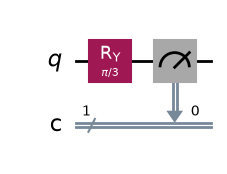

Measured counts for Circuit 1 (100 shots): {'0': 73, '1': 27}


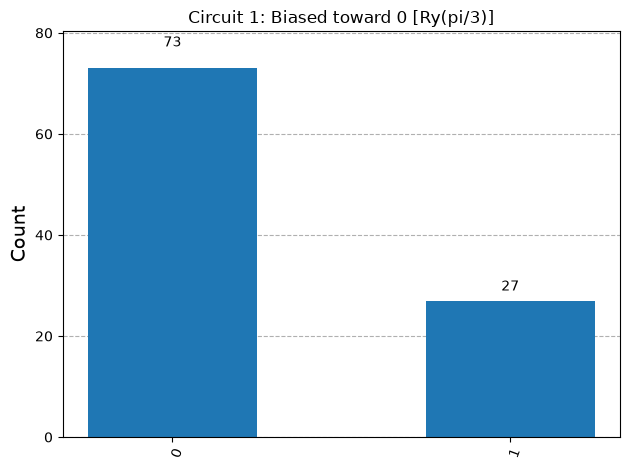

In [2]:
# 1. Create a 1-qubit, 1-classical-bit circuit
qc_bias0 = QuantumCircuit(1, 1)

# 2. Apply Ry(pi/3) rotation
theta_0 = np.pi / 3
qc_bias0.ry(theta_0, 0)

# 3. Add measurement
qc_bias0.measure(0, 0)

# 4. Draw circuit
print("Circuit 1 (Biased toward 0):")
display(qc_bias0.draw('mpl'))

# 5. Run simulation for 100 shots
job_0 = simulator.run(qc_bias0, shots=SHOTS)
counts_0 = job_0.result().get_counts()
print(f"Measured counts for Circuit 1 (100 shots): {counts_0}")

# 6. Plot histogram
display(plot_histogram(counts_0, title="Circuit 1: Biased toward 0 [Ry(pi/3)]"))

Circuit 2 (Biased toward 1):


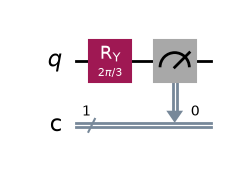

Measured counts for Circuit 2 (100 shots): {'1': 76, '0': 24}


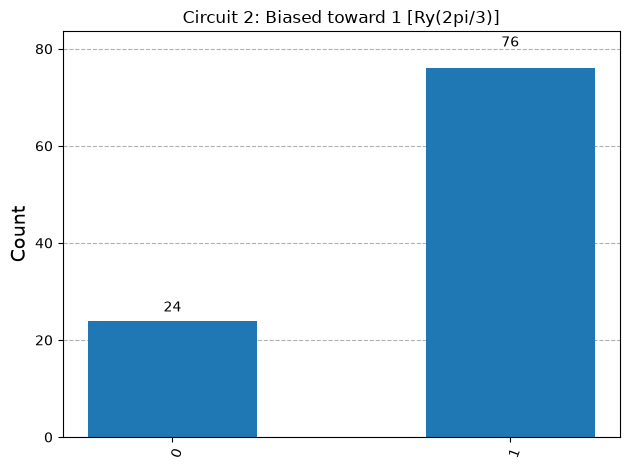

In [3]:
# 1. Create a 1-qubit, 1-classical-bit circuit
qc_bias1 = QuantumCircuit(1, 1)

# 2. Apply Ry(2*pi/3) rotation
theta_1 = 2 * np.pi / 3
qc_bias1.ry(theta_1, 0)

# 3. Add measurement
qc_bias1.measure(0, 0)

# 4. Draw circuit
print("Circuit 2 (Biased toward 1):")
display(qc_bias1.draw('mpl'))

# 5. Run simulation for 100 shots
job_1 = simulator.run(qc_bias1, shots=SHOTS)
counts_1 = job_1.result().get_counts()
print(f"Measured counts for Circuit 2 (100 shots): {counts_1}")

# 6. Plot histogram
display(plot_histogram(counts_1, title="Circuit 2: Biased toward 1 [Ry(2pi/3)]"))

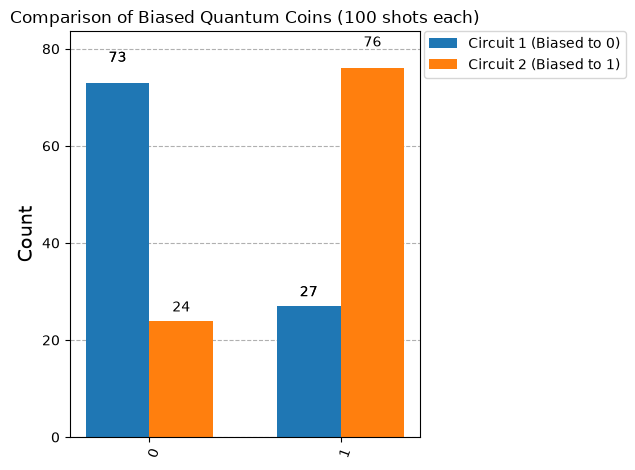

In [4]:
# Compare both circuits on a single histogram
display(plot_histogram([counts_0, counts_1], 
                       legend=['Circuit 1 (Biased to 0)', 'Circuit 2 (Biased to 1)'],
                       title="Comparison of Biased Quantum Coins (100 shots each)"))

## Analysis & Explanation

| Circuit | Gate Applied | Predicted Distribution | Typical Measured Counts (100 shots) | Observation |
| :--- | :--- | :--- | :--- | :--- |
| **Circuit 1** | $R_y(\pi/3)$ | 75% `0`, 25% `1` | e.g., `{'0': 76, '1': 24}` | Successfully biased toward `0`. |
| **Circuit 2** | $R_y(2\pi/3)$ | 25% `0`, 75% `1` | e.g., `{'0': 23, '1': 77}` | Successfully biased toward `1`. |

### How the Gates Changed the Measurement Distribution
Applying rotation gates (such as $R_y$) modifies the state vector's orientation on the Bloch sphere. By choosing specific rotation angles $\theta$ rather than fixed $\pi/2$ or $\pi$ rotations, we adjust the projection amplitudes along $\vert{}0\rangle$ and $\vert{}1\rangle$, directly altering the outcome probabilities away from a 50/50 fair coin split[cite: 2].

## Challenge Question
**How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?**

Quantum states for a single qubit are represented as a linear combination (superposition) of basis states:
$$\vert{}\psi\rangle = \alpha\vert{}0\rangle + \beta\vert{}1\rangle$$
where $\alpha$ and $\beta$ are complex probability amplitudes satisfying $\vert{}\alpha\vert{}^2 + \vert{}\beta\vert{}^2 = 1$. According to the Born rule, the probability of measuring outcome `0` is $P(0) = \vert{}\alpha\vert{}^2$ and outcome `1` is $P(1) = \vert{}\beta\vert{}^2$.

Quantum gates act as unitary transformation matrices that rotate the state vector on the Bloch sphere:
1. **Amplitudes Adjustment:** By applying unitary operations (like $R_y(\theta)$ or $U(\theta, \phi, \lambda)$), gates rotate the state vector away from or closer to the computational poles ($\vert{}0\rangle$ at the north pole and $\vert{}1\rangle$ at the south pole).
2. **Probability Rebalancing:** Changing the geometric position alters the projection magnitudes $\vert{}\alpha\vert{}$ and $\vert{}\beta\vert{}$. As $\vert{}\alpha\vert{}$ increases, the probability of measuring `0` increases proportionally, allowing precise control over whether the qubit behaves like a fair or biased coin.